In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#plot style
sns.set_theme(style='whitegrid')
plt.rcParams["figure.figsize"]=(10,6)
plt.rcParams["figure.dpi"]=100

%matplotlib inline

In [6]:
df=pd.read_csv('data/titanic.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Missing Values

In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

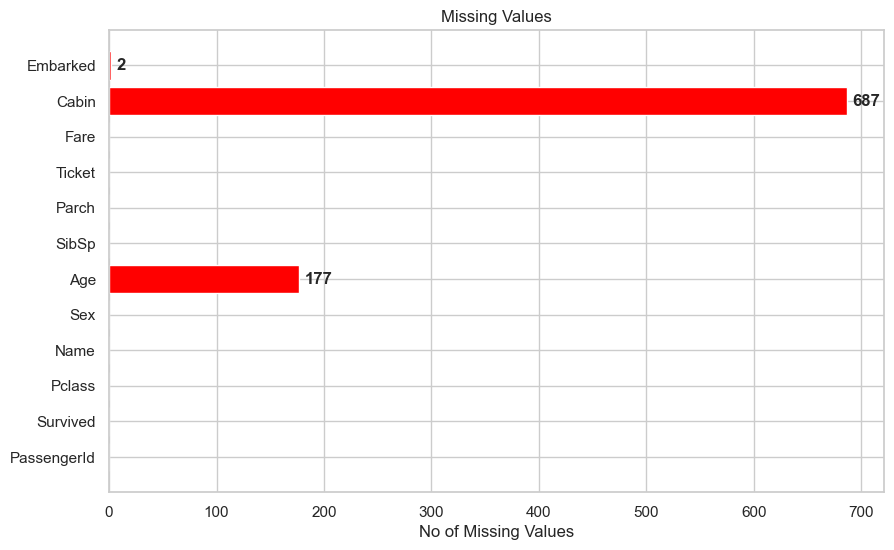

In [17]:
# fig,ax=plt.subplots(figsize=(10,4))
fig,ax=plt.subplots()
ax.barh(df.columns,df.isnull().sum(),color="red")
ax.set_title("Missing Values")
ax.set_xlabel("No of Missing Values")

for i,v in enumerate(df.isnull().sum()):
    if v>0:
        ax.text(v+5,i,v,va="center",fontweight="bold")
plt.show()

**Cabin** has too many missing values so better to drop

**age** and **embarked** can be filled with `mean` and `mode`

## Survival

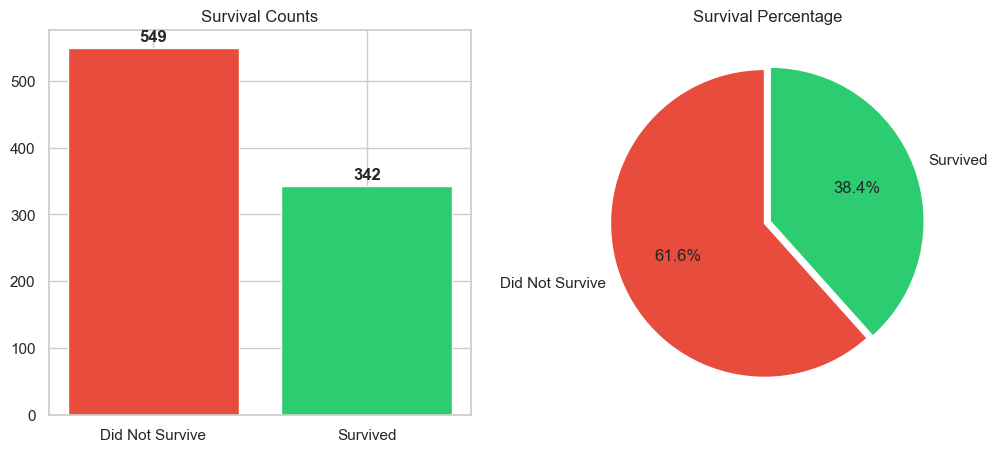

In [34]:
fig,ax=plt.subplots(1,2,figsize=(12,5))

survival_counts=df["Survived"].value_counts()
#[0]=Not Survived, [1]=Survived

ax[0].bar(["Did Not Survive","Survived"],survival_counts,color=["#e74c3c", "#2ecc71"])
ax[0].set_title("Survival Counts")
for i,c in enumerate(survival_counts.values):
    ax[0].text(i,c+10,c,ha="center",fontweight="bold")

ax[1].pie(survival_counts,labels=["Did Not Survive","Survived"],autopct="%1.1f%%",colors=["#e74c3c", "#2ecc71"],startangle=90,explode=(.02,.02))
ax[1].set_title("Survival Percentage")
plt.show()

## Uni Variate Analysis - Numerical Features

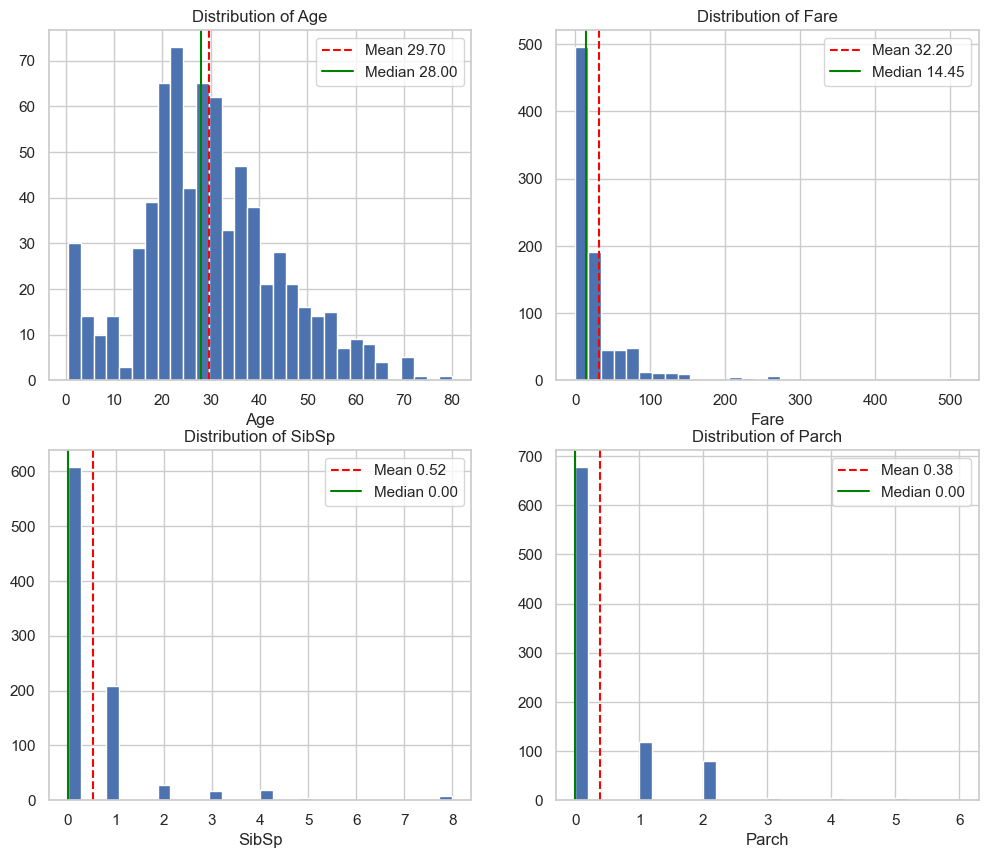

In [45]:
cols=["Age","Fare","SibSp","Parch"]

fig,ax=plt.subplots(2,2,figsize=(12,10))
# print(ax)
ax=ax.flatten()
# print(ax)
for i,col in enumerate(cols):
    ax[i].hist(df[col].dropna(),bins=30)
    ax[i].set_title(f"Distribution of {col}")
    ax[i].axvline(df[col].mean(),color = "red", linestyle="--",label=f"Mean {df[col].mean():.2f}")
    ax[i].axvline(df[col].median(),color="green",label=(f"Median {df[col].median():.2f}"))
    ax[i].set_xlabel(col)
    ax[i].legend()
plt.show()

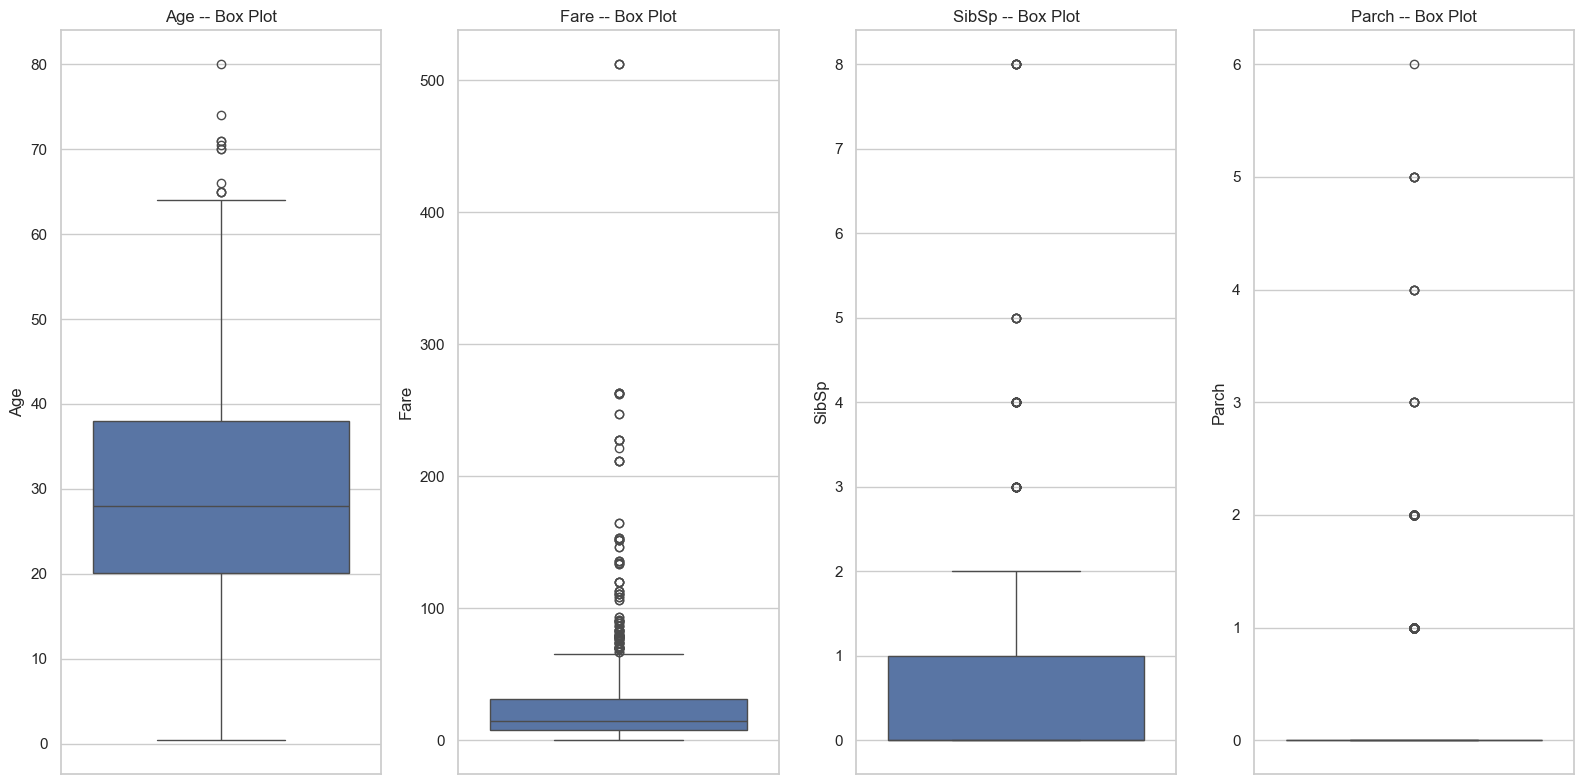

In [51]:
#boxplots
fig,ax=plt.subplots(1,4,figsize=(16,8))

for i,col in enumerate(cols):
    sns.boxplot(y=df[col],ax=ax[i])
    ax[i].set_title(f"{col} -- Box Plot")
plt.tight_layout()
plt.show()

## Univariate Analysis — Categorical

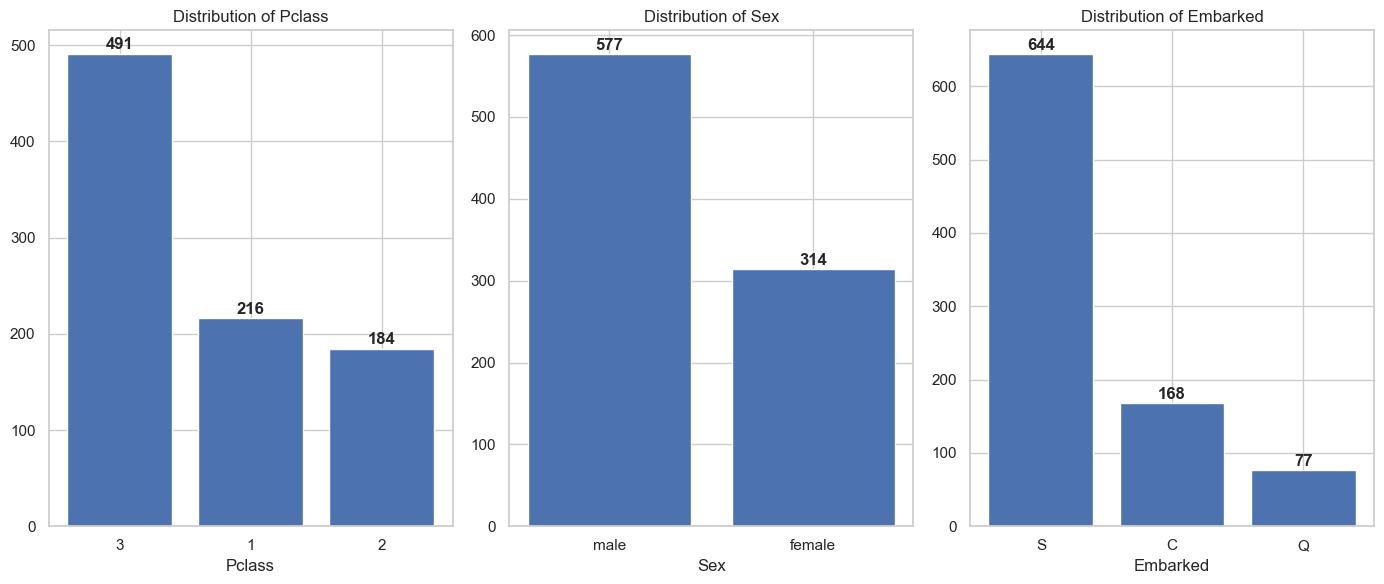

In [68]:
cat_cols=["Pclass", "Sex", "Embarked"]

fig,ax=plt.subplots(1,3,figsize=(14,6))
                    
for i,col in enumerate(cat_cols):
    counts=df[col].value_counts()
    ax[i].bar(counts.index.astype(str),counts.values)
    ax[i].set_title(f"Distribution of {col}")
    ax[i].set_xlabel(col)
    for idx,c in enumerate(counts.values):
        ax[i].text(idx,c+5,c,ha="center",fontweight="bold")
plt.tight_layout()
plt.show()

## Bivariate Analysis

In [76]:
by_sex=df.groupby("Sex")["Survived"].mean()
print(by_sex)
by_class=df.groupby("Pclass")["Survived"].mean()
print(by_class)
by_embarked=df.groupby("Embarked")["Survived"].mean()
print(by_embarked)

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64


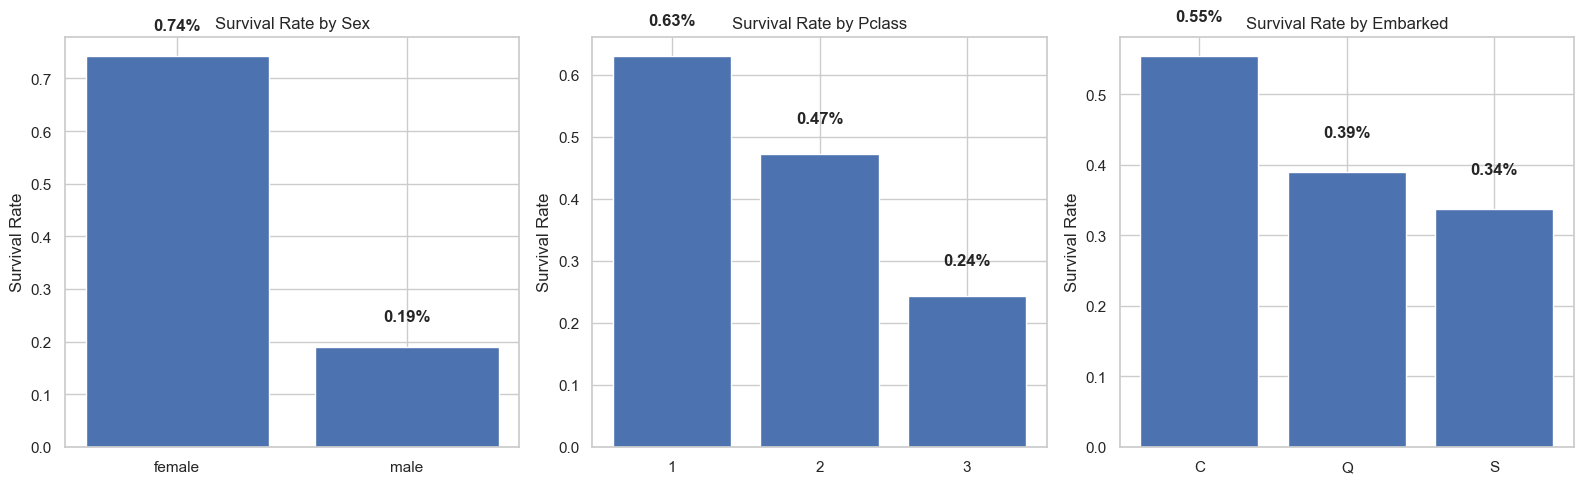

In [86]:
fig,ax=plt.subplots(1,3,figsize=(16,5))
bi_classes=[by_sex,by_class,by_embarked]

for i,col in enumerate(bi_classes):
    ax[i].bar(col.index.astype(str),col.values)
    ax[i].set_ylabel("Survival Rate")
    ax[i].set_title(f"Survival Rate by {col.index.name}")
    for idx,v in enumerate(col.values):
        ax[i].text(idx,v+.05,f"{v:.2f}%",ha="center",fontweight="bold")
plt.tight_layout()
plt.show()

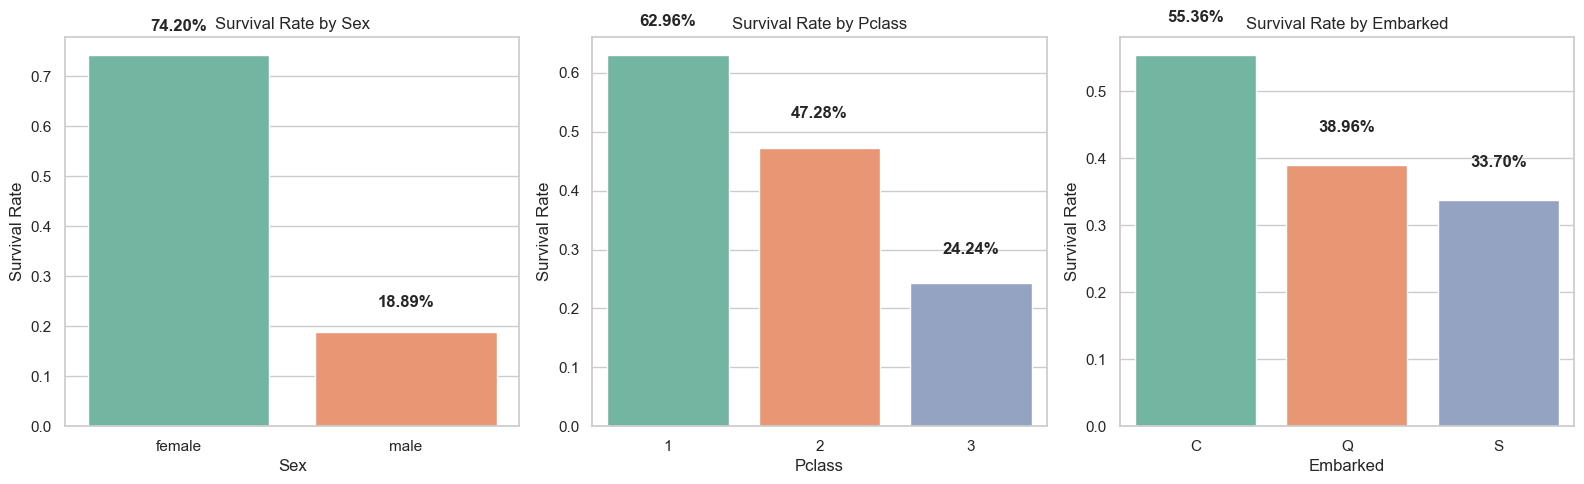

In [99]:
fig,ax=plt.subplots(1,3,figsize=(16,5))
sns.set_theme(style="whitegrid",palette="Set2")
for i,col in enumerate(bi_classes):
    sns.barplot(x=col.index.astype(str),y=col.values,ax=ax[i],hue=col.index.astype(str))
    # sns.set_title(f"Survival Rate by {col.index.name}")
    # sns.set_ylabel("Survival Rate")
    ax[i].set_ylabel("Survival Rate")
    ax[i].set_title(f"Survival Rate by {col.index.name}")
    for idx,v in enumerate(col.values):
        ax[i].text(idx,v+.05,f"{v*100:.2f}%",ha="center",fontweight="bold")
plt.tight_layout()
plt.show()

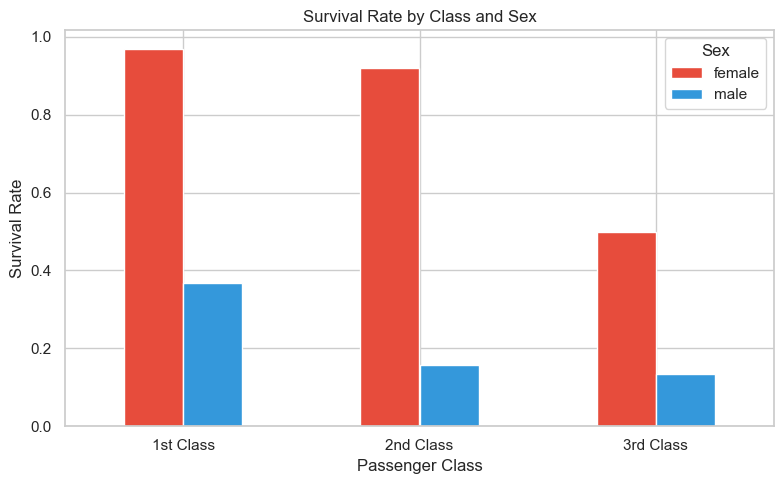

In [98]:
# Survival by Sex and Pclass combined
fig, ax = plt.subplots(figsize=(8, 5))
survival_grouped = df.groupby(["Pclass", "Sex"])["Survived"].mean().unstack()
survival_grouped.plot(kind="bar", ax=ax, color=["#e74c3c", "#3498db"])
ax.set_title("Survival Rate by Class and Sex")
ax.set_ylabel("Survival Rate")
ax.set_xlabel("Passenger Class")
ax.set_xticklabels(["1st Class", "2nd Class", "3rd Class"], rotation=0)
ax.legend(title="Sex")
plt.tight_layout()
plt.show()

- Women had higher rate of survival (74% compared to 19%)
- 1st class has significantly high survival rate than 3rd class (63% and 24%)
- people from port C(Cherbourg) survived more

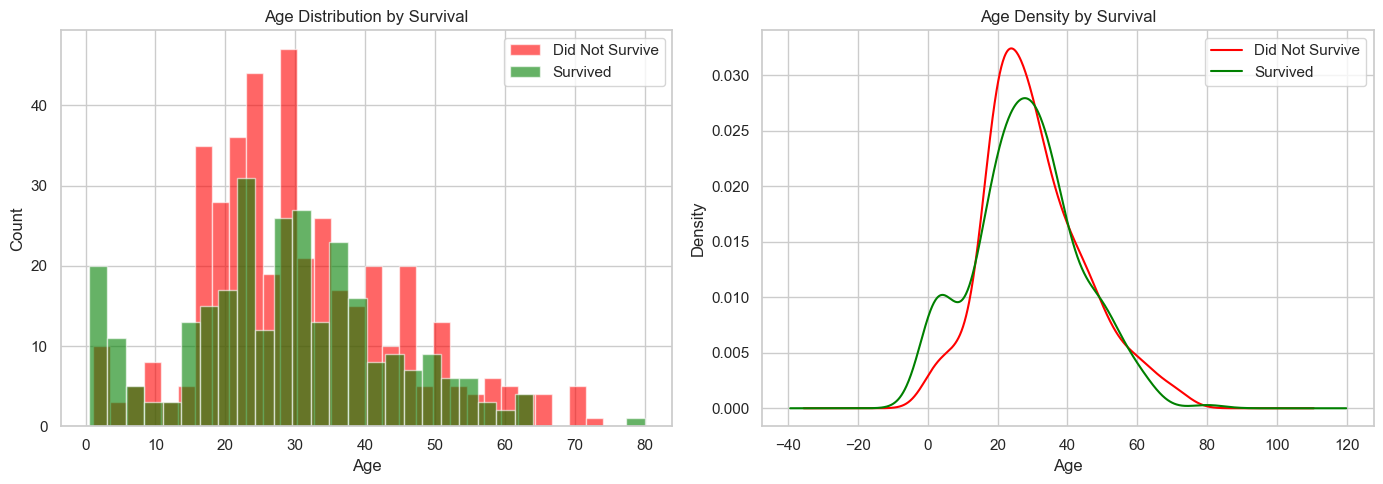

In [103]:
# Age distribution by survival
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overlapping histograms
axes[0].hist(df[df["Survived"] == 0]["Age"].dropna(), bins=30, alpha=0.6,
             color="red", label="Did Not Survive", edgecolor="white")
axes[0].hist(df[df["Survived"] == 1]["Age"].dropna(), bins=30, alpha=0.6,
             color="green", label="Survived", edgecolor="white")
axes[0].set_title("Age Distribution by Survival")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")
axes[0].legend()

# KDE plot
df[df["Survived"] == 0]["Age"].dropna().plot.kde(ax=axes[1], color="red",
                                                  label="Did Not Survive")
df[df["Survived"] == 1]["Age"].dropna().plot.kde(ax=axes[1], color="green",
                                                  label="Survived")
axes[1].set_title("Age Density by Survival")
axes[1].set_xlabel("Age")
axes[1].legend()

plt.tight_layout()
plt.show()


Children had higher survival rate

C:\Users\indur\AppData\Local\Temp\ipykernel_14976\26388354.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Did Not Survive", "Survived"])


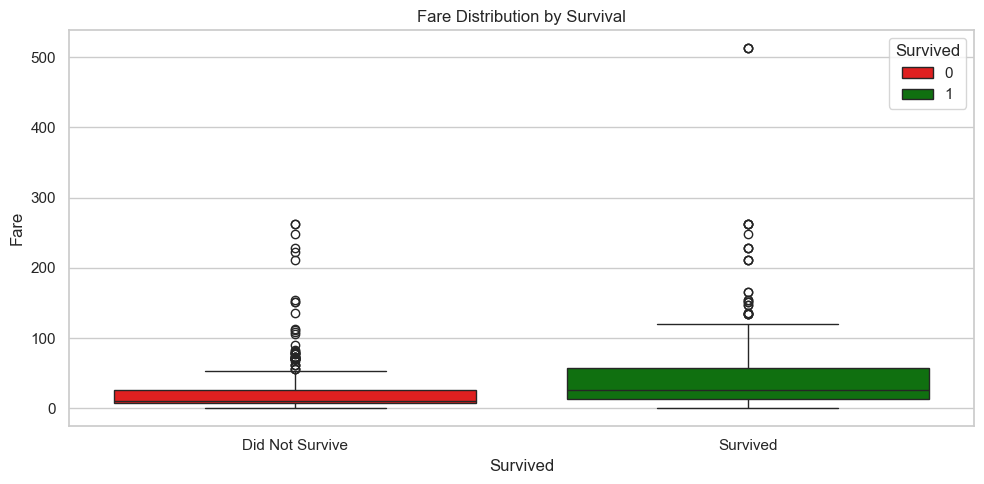

Average fare — Survived: $48.40
Average fare — Did Not Survive: $22.12


In [102]:
# Fare distribution by survival
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x="Survived", y="Fare", data=df, palette=["red", "green"],hue="Survived", ax=ax)
ax.set_xticklabels(["Did Not Survive", "Survived"])
ax.set_title("Fare Distribution by Survival")
ax.set_ylabel("Fare")
plt.tight_layout()
plt.show()

print(f"Average fare — Survived: ${df[df['Survived']==1]['Fare'].mean():.2f}")
print(f"Average fare — Did Not Survive: ${df[df['Survived']==0]['Fare'].mean():.2f}")